<div class="alert alert-success py-2 px-3 mb-2"
     style="font-family: 'Montserrat', sans-serif; font-size: 13px;">

<style>
.alert code {
    background: transparent !important;
    color: inherit !important;
    padding: 0 !important;
    font-family: 'Inter', sans-serif !important;
    font-size: 13px !important;
}
</style>

<strong>Lab 03 – Datasets Operations</strong>

<strong>Notes:</strong> <code>notes/03-datasets-operations.md</code> ·
<strong>Result:</strong> <code>results/03-datasets-operations.md</code>

<strong>Goal:</strong> Load, inspect, transform, save, and push a dataset.

<strong>Needs:</strong> <code>HF_WRITE_TOKEN</code> in the repository-root <code>.env</code> file.

<strong>Install:</strong> <code>pip install datasets</code>

<strong>Warning:</strong> The Hub repository and local files created by this lab are deleted in the cleanup cell.

</div>

In [8]:
! uv pip uninstall numpy scipy pandas
! uv pip install "numpy>=2.0.2" "scipy>=1.14" "pandas>=3.1.1"

Using Python 3.12.11 environment at: /home/zeus/miniconda3/envs/cloudspace
Uninstalled 3 packages in 433ms
 - numpy==1.26.4
 - pandas==3.1.1
 - scipy==1.13.1
Using Python 3.12.11 environment at: /home/zeus/miniconda3/envs/cloudspace
Resolved 5 packages in 15ms                                          
Installed 3 packages in 180ms                               
 + numpy==2.5.5
 + pandas==3.1.1
 + scipy==1.18.1


In [1]:
import numpy as np
import pandas as pd
import scipy

print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("scipy:", scipy.__version__)

numpy: 2.5.5
pandas: 3.1.1
scipy: 1.18.1


In [16]:
# ── Lab 03 - Datasets Operations ──
# Notes : notes/03-datasets-operations.md
# Result: results/03-datasets-operations.md
# Goal  : load, inspect, transform, save and push a dataset
# Needs : HF_WRITE_TOKEN in the repo-root .env
# Install: pip install datasets
# Note  : the Hub repos and local files are deleted in the cleanup cell

# ── folders: datasets/ sits next to labs/ ──
import os
from pathlib import Path

ROOT = Path.cwd().parent
DATASETS_DIR = ROOT / "datasets"
DOWNLOAD_DIR = DATASETS_DIR / "downloads"   # everything pulled from the Hub
UPLOAD_DIR = DATASETS_DIR / "upload"        # everything we push to the Hub
FILES_DIR = UPLOAD_DIR / "sample_files"     # loose csv / parquet / jsonl / txt files
for folder in (DOWNLOAD_DIR, UPLOAD_DIR, FILES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# ── send every cache into datasets/downloads ──
# Must run BEFORE huggingface_hub / datasets / transformers are imported
os.environ["HF_HUB_CACHE"] = str(DOWNLOAD_DIR / "hub_cache")
os.environ["HF_DATASETS_CACHE"] = str(DOWNLOAD_DIR / "datasets_cache")

# ── imports ──
import shutil
from dotenv import load_dotenv
import datasets
from datasets import Dataset, DatasetDict, load_dataset, load_from_disk
from huggingface_hub import HfApi, constants

# ── check: caches really moved (restart the kernel if this fails) ──
# assert str(DOWNLOAD_DIR) in constants.HF_HUB_CACHE, "Restart the kernel, then run Cell 1 first"

# ── load the write token from .env ──
load_dotenv()
WRITE_TOKEN = os.environ["HF_WRITE_TOKEN"]
os.environ.pop("HF_TOKEN", None)

# ── user name and the repos we will create later ──
api = HfApi(token=WRITE_TOKEN)
USER = api.whoami()["name"]
DATASET_REPO = f"{USER}/datasets-lab-tiny"
FILES_REPO = f"{USER}/datasets-lab-files"

print("datasets version:", datasets.__version__)
print("files folder    :", FILES_DIR)
print("dataset repo    :", DATASET_REPO)

datasets version: 5.2.0
files folder    : /teamspace/studios/this_studio/All-about-finetuning/finetuning/00_platform/datasets/upload/sample_files
dataset repo    : akshayredekar74/datasets-lab-tiny


In [3]:
# ── 1. build a dataset from a dictionary ──
# Each key is a column, each list holds that column's values

data = {
    "text": [
        "great movie",
        "terrible acting and a boring plot",
        "loved every minute",
        "not worth the money",
        "a true masterpiece of cinema",
        "I fell asleep",
        "funny and warm",
        "the ending ruined it",
        "beautiful music",
        "too long and too loud",
        "would watch again",
        "a complete mess",
    ],
    "label": [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0],   # 1 = good, 0 = bad
}

ds = Dataset.from_dict(data)
print(ds)

Dataset({
    features: ['text', 'label'],
    num_rows: 12
})


In [4]:
# ── 2. inspect a dataset ──

print("rows    :", ds.num_rows)
print("columns :", ds.column_names)
print("features:", ds.features)

# ── one row, several rows, one column ──
print("row 0   :", ds[0])
print("rows 0-1:", ds[:2])
print("texts   :", ds["text"][:3])

rows    : 12
columns : ['text', 'label']
features: {'text': Value('string'), 'label': Value('int64')}
row 0   : {'text': 'great movie', 'label': 1}
rows 0-1: {'text': ['great movie', 'terrible acting and a boring plot'], 'label': [1, 0]}
texts   : ['great movie', 'terrible acting and a boring plot', 'loved every minute']


In [26]:
# ── 2a. rows and columns ──
print("shape       :", ds.shape)                # (rows, columns)
print("last row    :", ds[-1])
print("rows 0 and 2:", ds[[0, 2]])
print("slice [0:2] :", ds[0:2])                 # dict of lists

# ── one column (newer versions return a Column object, it works like a list) ──
texts = ds["text"]
print("type        :", type(texts))
print("first text  :", texts[0])

# ── loop over rows ──
for i, row in enumerate(ds.select(range(3))):
    print(f"  row {i}: {row['text']!r} -> {row['label']}")

shape       : (12, 3)
last row    : {'text': 'a complete mess', 'label': 0, 'n_words': 3}
rows 0 and 2: {'text': ['great movie', 'loved every minute'], 'label': [1, 1], 'n_words': [2, 3]}
slice [0:2] : {'text': ['great movie', 'terrible acting and a boring plot'], 'label': [1, 0], 'n_words': [2, 6]}
type        : <class 'datasets.arrow_dataset.Column'>
first text  : great movie
  row 0: 'great movie' -> 1
  row 1: 'terrible acting and a boring plot' -> 0
  row 2: 'loved every minute' -> 1


In [27]:
# ── 2b. convert to plain Python ──
as_dict = ds.to_dict()           # {"text": [...], "label": [...]}
as_list = ds.to_list()           # [{"text": ..., "label": ...}, ...]
as_df = ds.to_pandas()           # pandas table

print("keys     :", list(as_dict.keys()))
print("first row:", as_list[0])
print(as_df["label"].value_counts())

# ── features behave like a dict ──
for name, feature in ds.features.items():
    print(f"  {name!r:8} -> {feature}")
print("'text' in features :", "text" in ds.features)
print("'score' in features:", "score" in ds.features)

# ── normal Python tools work too ──
from collections import Counter
print("label counts:", dict(Counter(ds["label"])))
print("upper texts :", [r["text"].upper() for r in ds.select(range(2))])
print("label 1 only:", [r["text"] for r in ds if r["label"] == 1][:3])

keys     : ['text', 'label', 'n_words']
first row: {'text': 'great movie', 'label': 1, 'n_words': 2}
label
1    6
0    6
Name: count, dtype: int64
  'text'   -> Value('string')
  'label'  -> Value('int64')
  'n_words' -> Value('int64')
'text' in features : True
'score' in features: False
label counts: {1: 6, 0: 6}
upper texts : ['GREAT MOVIE', 'TERRIBLE ACTING AND A BORING PLOT']
label 1 only: ['great movie', 'loved every minute', 'a true masterpiece of cinema']


In [28]:
# ── 3. load a public dataset ──
# split="train[:200]" means: only the first 200 rows

movies = load_dataset(
    "cornell-movie-review-data/rotten_tomatoes",
    split="train[:200]",
)

print(movies)
print("first row:", movies[0])

Dataset({
    features: ['text', 'label'],
    num_rows: 200
})
first row: {'text': 'the rock is destined to be the 21st century\'s new " conan " and that he\'s going to make a splash even greater than arnold schwarzenegger , jean-claud van damme or steven segal .', 'label': 1}


In [30]:
# ── 3a. loading variants ──
# rotten_tomatoes is small, so every line runs fast

all_splits = load_dataset("cornell-movie-review-data/rotten_tomatoes",)                            # every split
train_only = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train")             # one split
first_10pct = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train[:10%]")      # first 10 percent
rows_100_200 = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train[100:200]")  # row range
train_plus_test = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train+test")   # merge two splits

print("splits       :", list(all_splits.keys()))
print("train        :", train_only.num_rows)
print("first 10%    :", first_10pct.num_rows)
print("rows 100:200 :", rows_100_200.num_rows)
print("train + test :", train_plus_test.num_rows)

# ── a dataset with a config (sub-dataset) ──
mrpc = load_dataset("nyu-mll/glue", "mrpc")
print(mrpc)

splits       : ['train', 'validation', 'test']
train        : 8530
first 10%    : 853
rows 100:200 : 100
train + test : 9596


README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})


In [31]:
# ── 3b. load from local files ──
import pandas as pd

# ── make sample files (one small table, four formats) ──
sample = pd.DataFrame({
    "text": [
        "I love this movie, it's great!",
        "This film is terrible and boring.",
        "The weather today is just okay.",
        "Best day ever!",
        "I hate long meetings.",
    ],
    "label": ["positive", "negative", "neutral", "positive", "negative"],
})
sample.to_csv(FILES_DIR / "data.csv", index=False)
sample.to_json(FILES_DIR / "data.jsonl", orient="records", lines=True)
sample.to_parquet(FILES_DIR / "data.parquet", index=False)
(FILES_DIR / "data.txt").write_text("first line\nsecond line\nthird line\n")

# ── load each format ──
for kind, filename in [("csv", "data.csv"), ("json", "data.jsonl"),
                       ("parquet", "data.parquet"), ("text", "data.txt")]:
    loaded = load_dataset(kind, data_files=str(FILES_DIR / filename))
    print(f"{kind:8}", loaded["train"].column_names, loaded["train"].num_rows, "rows")

# ── several files mapped to splits ──
load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train[:100]").to_csv(str(FILES_DIR / "train.csv"))
load_dataset("cornell-movie-review-data/rotten_tomatoes", split="validation[:50]").to_csv(str(FILES_DIR / "test.csv"))

two_files = load_dataset("csv", data_files={
    "train": str(FILES_DIR / "train.csv"),
    "test": str(FILES_DIR / "test.csv"),
})
print(two_files)

Generating train split: 0 examples [00:00, ? examples/s]

csv      ['text', 'label'] 5 rows


Generating train split: 0 examples [00:00, ? examples/s]

json     ['text', 'label'] 5 rows


Generating train split: 0 examples [00:00, ? examples/s]

parquet  ['text', 'label'] 5 rows


... (3 outputs left out)

Creating CSV from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 100
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 50
    })
})


In [32]:
# ── 3c. build from Python objects ──
from_df = Dataset.from_pandas(pd.DataFrame({"text": ["a", "b"], "label": [1, 0]}))
from_rows = Dataset.from_list([
    {"text": "hello", "label": 0},
    {"text": "world", "label": 1},
])

print(from_df)
print(from_rows)
print("rows:", len(from_rows))

Dataset({
    features: ['text', 'label'],
    num_rows: 2
})
Dataset({
    features: ['text', 'label'],
    num_rows: 2
})
rows: 2


In [33]:
# ── 4. map: add a new column ──
# map runs a function on every row

def add_word_count(row):
    return {"n_words": len(row["text"].split())}

ds = ds.map(add_word_count)
print(ds.column_names)
print(ds[0])

Map:   0%|          | 0/12 [00:00<?, ? examples/s]

['text', 'label', 'n_words']
{'text': 'great movie', 'label': 1, 'n_words': 2}


In [35]:
# ── 4a. map: normal vs batched vs num_proc ──
# load_from_cache_file=False so each run does the real work
import time

rt = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train")     # about 8,500 rows

def add_length(row):                  # one row at a time
    return {"n_chars": len(row["text"])}

def add_length_batched(batch):        # many rows at a time
    return {"n_chars": [len(t) for t in batch["text"]]}

start = time.time()
rt.map(add_length, load_from_cache_file=False)
print("normal  :", round(time.time() - start, 2), "s")

start = time.time()
rt.map(add_length_batched, batched=True, batch_size=128, load_from_cache_file=False)
print("batched :", round(time.time() - start, 2), "s")

# ── 2 worker processes (for tiny functions this can be slower) ──
start = time.time()
rt.map(add_length, num_proc=2, load_from_cache_file=False)
print("num_proc:", round(time.time() - start, 2), "s")

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

normal  : 0.49 s


Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

batched : 0.07 s


Map (num_proc=2):   0%|          | 0/8530 [00:00<?, ? examples/s]

num_proc: 0.6 s


In [37]:
# ── 4b. map with a tokenizer (the most common real use) ──
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=64)

# ── on a DatasetDict, map runs on every split at once ──
rt_dict = load_dataset("cornell-movie-review-data/rotten_tomatoes",)
tokenized = rt_dict.map(tokenize, batched=True, remove_columns=["text"])

print(tokenized)
print("columns:", tokenized["train"].column_names)

Map:   0%|          | 0/8530 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

Map:   0%|          | 0/1066 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1066
    })
})
columns: ['label', 'input_ids', 'token_type_ids', 'attention_mask']


In [22]:
ds

Dataset({
    features: ['text', 'label', 'n_words'],
    num_rows: 12
})

In [7]:
# ── 5. filter: keep only some rows ──
# The function returns True for rows we want to keep

long_reviews = ds.filter(lambda row: row["n_words"] >= 4)
print("before:", ds.num_rows, "rows")
print("after :", long_reviews.num_rows, "rows")
print(long_reviews["text"])

Filter:   0%|          | 0/12 [00:00<?, ? examples/s]

before: 12 rows
after : 5 rows
Column(['terrible acting and a boring plot', 'not worth the money', 'a true masterpiece of cinema', 'the ending ruined it', 'too long and too loud'])


In [38]:
# ── 6. select, shuffle, sort ──

# ── pick rows by position ──
print("first 3:", ds.select(range(3))["text"])

# ── shuffle (seed makes it repeatable) ──
print("shuffled:", ds.shuffle(seed=42)["text"][:3])

# ── sort by a column ──
print("shortest:", ds.sort("n_words")["text"][:3])

first 3: Column(['great movie', 'terrible acting and a boring plot', 'loved every minute'])
shuffled: ['great movie', 'the ending ruined it', 'funny and warm']
shortest: ['great movie', 'beautiful music', 'loved every minute']


/home/zeus/miniconda3/envs/cloudspace/lib/python3.12/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in SortOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)


In [39]:
# ── 6a. more row operations ──
print("sorted desc :", ds.sort("label", reverse=True)["label"][:6])
print("skip first 3:", ds.skip(3).num_rows)
print("take first 3:", ds.take(3).num_rows)

# ── filter with the row number ──
even_rows = ds.filter(lambda row, idx: idx % 2 == 0, with_indices=True)
print("even rows   :", even_rows.num_rows)

# ── shard: cut into equal chunks ──
for i in range(3):
    part = ds.shard(num_shards=3, index=i)
    print(f"shard {i}     :", part.num_rows, "rows")

sorted desc : [1, 1, 1, 1, 1, 1]
skip first 3: 9
take first 3: 3


Filter:   0%|          | 0/12 [00:00<?, ? examples/s]

even rows   : 6
shard 0     : 4 rows
shard 1     : 4 rows
shard 2     : 4 rows


In [40]:
# ── 7. rename and remove columns ──

renamed = ds.rename_column("label", "sentiment")
print("renamed:", renamed.column_names)

smaller = renamed.remove_columns(["n_words"])
print("smaller:", smaller.column_names)

renamed: ['text', 'sentiment', 'n_words']
smaller: ['text', 'sentiment']


In [41]:
# ── 7a. more column operations ──
from datasets import Value

# ── rename several columns in one call ──
print("rename_columns:", ds.rename_columns({"text": "review", "label": "sentiment"}).column_names)

with_source = ds.add_column("source", ["demo"] * ds.num_rows)
print("add_column    :", with_source.column_names)

as_float = ds.cast_column("label", Value("float32"))
print("cast_column   :", as_float.features["label"])

only_text = ds.select_columns(["text"])
print("select_columns:", only_text.column_names)

# ── flatten nested columns ──
nested = Dataset.from_dict({
    "question": ["How old are you?", "Where are you from?"],
    "answers": [
        {"text": ["25 years"], "start": [10]},
        {"text": ["India"], "start": [12]},
    ],
})
print("before flatten:", nested.column_names)
print("after flatten :", nested.flatten().column_names)

rename_columns: ['review', 'sentiment', 'n_words']
add_column    : ['text', 'label', 'n_words', 'source']


Casting the dataset:   0%|          | 0/12 [00:00<?, ? examples/s]

cast_column   : Value('float32')
select_columns: ['text']
before flatten: ['question', 'answers']
after flatten : ['question', 'answers.text', 'answers.start']


In [42]:
# ── 8. train / test split ──
# Gives a DatasetDict with two parts

split = ds.train_test_split(test_size=0.25, seed=42)
print(split)
print("train rows:", split["train"].num_rows)
print("test rows :", split["test"].num_rows)

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'n_words'],
        num_rows: 9
    })
    test: Dataset({
        features: ['text', 'label', 'n_words'],
        num_rows: 3
    })
})
train rows: 9
test rows : 3


In [43]:
# ── 8a. stratified split ──
# Keeps the label mix equal in train and test.
# Needs a ClassLabel column, so encode the labels first.
from collections import Counter

labelled = ds.class_encode_column("label")
strat = labelled.train_test_split(test_size=0.5, seed=42, stratify_by_column="label")

print("train labels:", dict(Counter(strat["train"]["label"])))
print("test labels :", dict(Counter(strat["test"]["label"])))

# ── a DatasetDict has no to_pandas(), pick a split first ──
print(strat["train"].to_pandas().head(3))

Stringifying the column:   0%|          | 0/12 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/12 [00:00<?, ? examples/s]

train labels: {1: 3, 0: 3}
test labels : {1: 3, 0: 3}
              text  label  n_words
0      great movie      1        2
1  beautiful music      1        2
2  a complete mess      0        3


In [44]:
import os
from pathlib import Path

ROOT = Path.cwd().parent
DATASETS_DIR = ROOT / "datasets"
DOWNLOAD_DIR = DATASETS_DIR / "downloads"   # everything pulled from the Hub
UPLOAD_DIR = DATASETS_DIR / "upload"        # everything we push to the Hub

In [45]:
# ── 9. save to disk ──
# save_to_disk keeps everything (columns, types, splits)

SAVED_DIR = UPLOAD_DIR / "tiny_dataset"
split.save_to_disk(str(SAVED_DIR))
reloaded = load_from_disk(str(SAVED_DIR))
print("reloaded:", reloaded)

Saving the dataset (0/1 shards):   0%|          | 0/9 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3 [00:00<?, ? examples/s]

reloaded: DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'n_words'],
        num_rows: 9
    })
    test: Dataset({
        features: ['text', 'label', 'n_words'],
        num_rows: 3
    })
})


In [46]:
# ── 10. export to files ──

ds.to_csv(str(FILES_DIR / "tiny.csv"))
ds.to_parquet(str(FILES_DIR / "tiny.parquet"))

# ── load the CSV back ──
from_csv = load_dataset("csv", data_files=str(FILES_DIR / "tiny.csv"), split="train")
print("from csv:", from_csv.num_rows, "rows")

# ── a pandas table, if you like tables ──
print(ds.to_pandas().head(3))

Creating CSV from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Generating train split: 0 examples [00:00, ? examples/s]

from csv: 12 rows
                                text  label  n_words
0                        great movie      1        2
1  terrible acting and a boring plot      0        6
2                 loved every minute      1        3


In [47]:
# ── 10a. concatenate two datasets ──
# Same columns, but the label NAMES differ, so a plain concatenate fails
from datasets import concatenate_datasets, interleave_datasets, ClassLabel, Features, Value

features_a = Features({"text": Value("string"), "label": ClassLabel(names=["neg", "pos"])})
features_b = Features({"text": Value("string"), "label": ClassLabel(names=["negative", "positive"])})

data_a = Dataset.from_dict(
    {"text": ["good", "bad", "fine"], "label": [1, 0, 1]}, features=features_a)
data_b = Dataset.from_dict(
    {"text": ["great", "awful", "nice", "poor", "superb"], "label": [1, 0, 1, 0, 1]},
    features=features_b)

# ── the error ──
try:
    concatenate_datasets([data_a, data_b])
except ValueError as e:
    print("error:", str(e)[:120])

# ── the fix: cast b to the schema of a ──
data_b = data_b.cast(data_a.features)
combined = concatenate_datasets([data_a, data_b])
print("combined rows:", combined.num_rows)      # 8

error: The features can't be aligned because the key label of features {'text': Value('string'), 'label': ClassLabel(names=['ne


Casting the dataset:   0%|          | 0/5 [00:00<?, ? examples/s]

combined rows: 8


In [48]:
# ── 10b. interleave: mix rows instead of stacking ──
mixed = interleave_datasets([data_a, data_b])
print("default (stops at the smaller one):", mixed.num_rows)         # 6
print("order:", mixed["text"])                                        # a, b, a, b ...

mixed_all = interleave_datasets([data_a, data_b], stopping_strategy="all_exhausted")
print("all_exhausted (repeats the smaller):", mixed_all.num_rows)    # 10

weighted = interleave_datasets([data_a, data_b], probabilities=[0.3, 0.7], seed=42)
print("weighted 30/70 rows:", weighted.num_rows)

default (stops at the smaller one): 6
order: Column(['good', 'great', 'bad', 'awful', 'fine', ...])
all_exhausted (repeats the smaller): 10
weighted 30/70 rows: 6


In [49]:
# ── 10c. export and framework formats ──
ds.to_json(str(FILES_DIR / "tiny.jsonl"))         # JSON lines

# ── set_format: columns come back as NumPy arrays (uses `tokenized` from 4b) ──
tokenized_train = tokenized["train"]
tokenized_train.set_format("numpy", columns=["input_ids", "attention_mask", "label"])
print("set_format :", type(tokenized_train[0]["input_ids"]))
tokenized_train.reset_format()                    # back to normal lists

# ── with_format: returns a NEW dataset, the original is untouched ──
numpy_ds = tokenized["train"].with_format("numpy")
print("with_format:", type(numpy_ds[0]["input_ids"]))

# ── PyTorch (needs torch installed) ──
# torch_ds = tokenized["train"].with_format("torch", columns=["input_ids", "label"])

Creating json from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

set_format : <class 'numpy.ndarray'>
with_format: <class 'numpy.ndarray'>


In [50]:
# ── 11. streaming ──
# Reads rows one by one, without downloading everything first.
# Useful for huge datasets.

stream = load_dataset("cornell-movie-review-data/rotten_tomatoes", split="train", streaming=True)

for row in stream.take(3):
    print(row["label"], "|", row["text"][:60])

1 | the rock is destined to be the 21st century's new " conan " 
1 | the gorgeously elaborate continuation of " the lord of the r
1 | effective but too-tepid biopic


In [51]:
# ── 12. push to the Hub ──
# Uploads the split as a private dataset repo

split.push_to_hub(DATASET_REPO, private=True, token=WRITE_TOKEN)
print("pushed: https://huggingface.co/datasets/" + DATASET_REPO)
print("files  :", api.list_repo_files(DATASET_REPO, repo_type="dataset"))

Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

... (3 outputs left out)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

pushed: https://huggingface.co/datasets/akshayredekar74/datasets-lab-tiny
files  : ['.gitattributes', 'README.md', 'data/test-00000-of-00001.parquet', 'data/train-00000-of-00001.parquet']


In [52]:
# ── 13. load it back from the Hub ──
# Private repo, so we pass the token

from_hub = load_dataset(DATASET_REPO, token=WRITE_TOKEN)
print(from_hub)
print("first train row:", from_hub["train"][0])

README.md:   0%|          | 0.00/420 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.95kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.78kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'n_words'],
        num_rows: 9
    })
    test: Dataset({
        features: ['text', 'label', 'n_words'],
        num_rows: 3
    })
})
first train row: {'text': 'too long and too loud', 'label': 0, 'n_words': 5}


In [53]:
# ── 13a. upload loose files to a dataset repo ──
# One commit for all files. This repo is only for file practice,
# so do not load_dataset() it.

FILES_REPO = f"{USER}/datasets-lab-files"
api.create_repo(FILES_REPO, repo_type="dataset", private=True, exist_ok=True)

api.upload_folder(
    folder_path=str(FILES_DIR),
    path_in_repo="data",
    repo_id=FILES_REPO,
    repo_type="dataset",
    allow_patterns=["*.txt", "*.parquet", "*.csv", "*.jsonl"],
    commit_message="Add sample files",
)
print(api.list_repo_files(FILES_REPO, repo_type="dataset"))

['.gitattributes', 'data/data.csv', 'data/data.jsonl', 'data/data.parquet', 'data/data.txt', 'data/test.csv', 'data/tiny.csv', 'data/tiny.jsonl', 'data/tiny.parquet', 'data/train.csv']


In [58]:
! uv pip install seaborn wordcloud

Using Python 3.12.11 environment at: /home/zeus/miniconda3/envs/cloudspace
Resolved 14 packages in 217ms                                        
⠙ Preparing packages... (0/1)                                                   
⠙ Preparing packages... (0/1)-------------------     0 B/541.86 KiB          
⠙ Preparing packages... (0/1)------------------- 16.00 KiB/541.86 KiB        
⠙ Preparing packages... (0/1)------------------- 32.00 KiB/541.86 KiB        
⠙ Preparing packages... (0/1)------------------- 48.00 KiB/541.86 KiB        
⠙ Preparing packages... (0/1)------------------- 63.59 KiB/541.86 KiB        
⠙ Preparing packages... (0/1)------------------- 79.59 KiB/541.86 KiB        
⠙ Preparing packages... (0/1)------------------- 95.59 KiB/541.86 KiB        
⠙ Preparing packages... (0/1)------------------- 111.59 KiB/541.86 KiB       
⠙ Preparing packages... (0/1)------------------- 127.59 KiB/541.86 KiB       
⠙ Preparing packages... (0/1)------------------- 143.59 KiB/541.86 KiB  

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

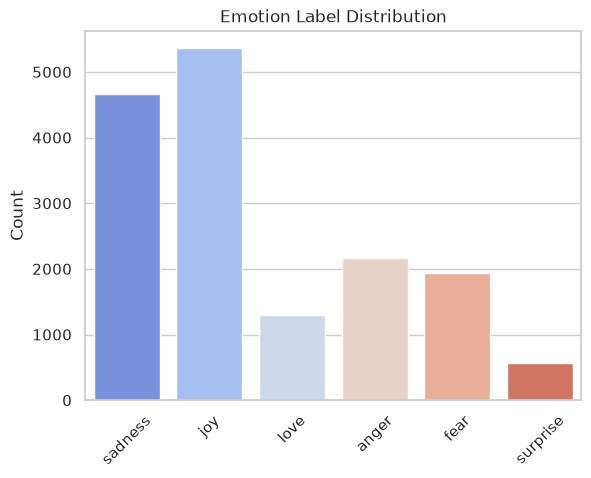

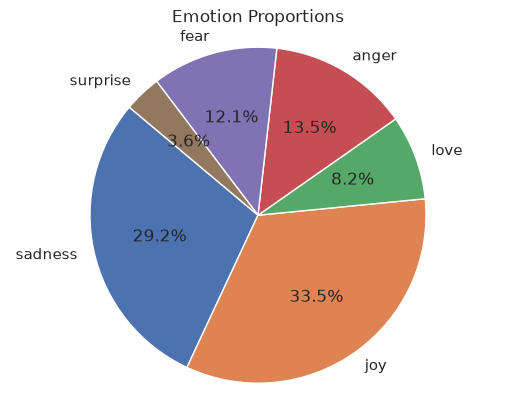

In [55]:
# ── 13b. explore a dataset: label counts ──
# Install once: pip install matplotlib seaborn wordcloud
# If "dair-ai/emotion" fails, use "emotion"
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

emotion = load_dataset("dair-ai/emotion")
label_names = emotion["train"].features["label"].names
label_counts = Counter(emotion["train"]["label"])
counts = [label_counts[i] for i in range(len(label_names))]

# ── bar chart ──
sns.barplot(x=label_names, y=counts, hue=label_names, palette="coolwarm", legend=False)
plt.title("Emotion Label Distribution")
plt.xticks(rotation=45)
plt.ylabel("Count")
plt.show()

# ── pie chart ──
plt.pie(counts, labels=label_names, autopct="%1.1f%%", startangle=140)
plt.title("Emotion Proportions")
plt.axis("equal")
plt.show()

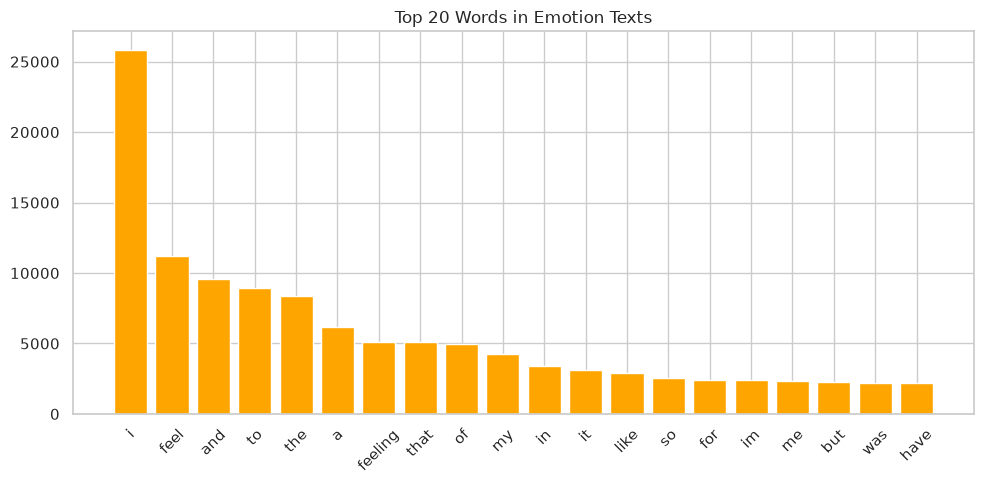

In [56]:
# ── 13c. most common words ──
emotion_df = emotion["train"].to_pandas()

words = re.findall(r"\w+", " ".join(emotion_df["text"]).lower())
top_words = Counter(words).most_common(20)
names, freq = zip(*top_words)

plt.figure(figsize=(10, 5))
plt.bar(names, freq, color="orange")
plt.xticks(rotation=45)
plt.title("Top 20 Words in Emotion Texts")
plt.tight_layout()
plt.show()

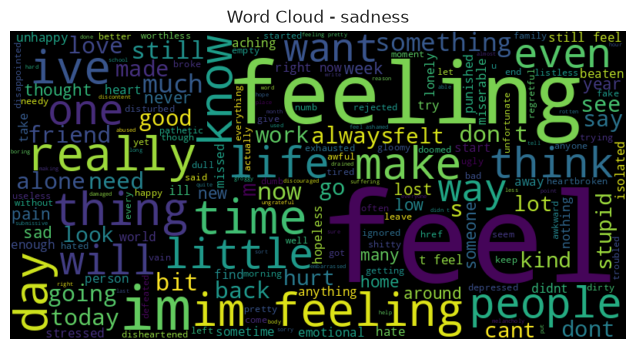

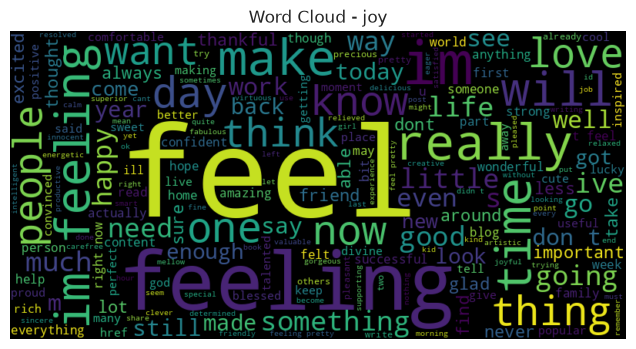

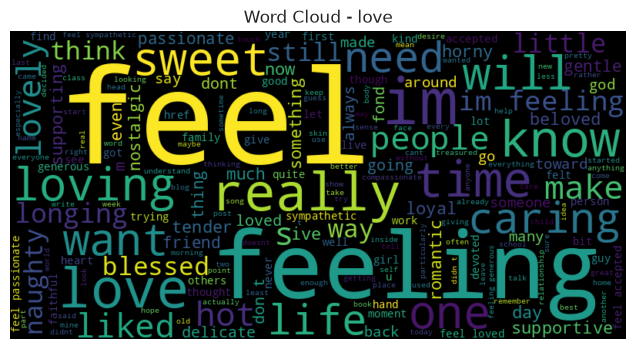

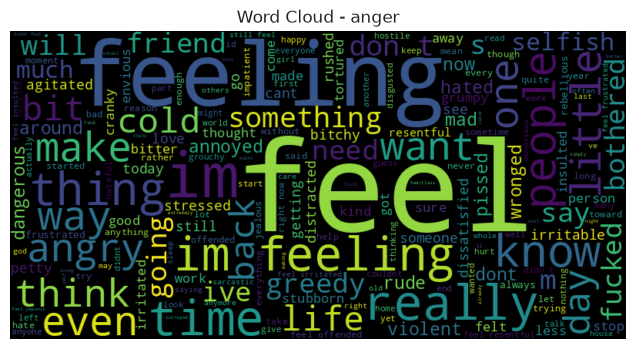

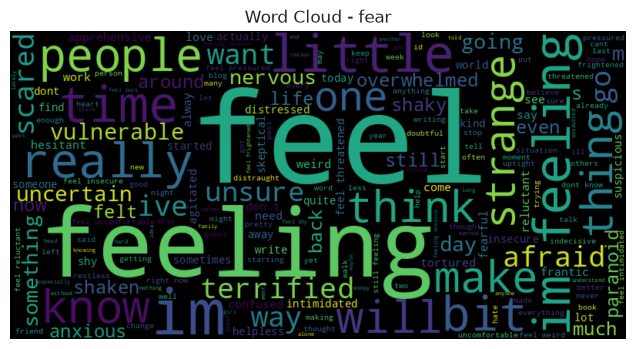

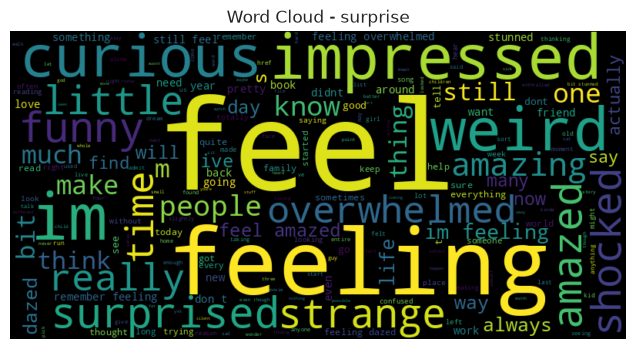

In [59]:
# ── 13d. word cloud per emotion ──
from wordcloud import WordCloud

for label_id, label_name in enumerate(label_names):
    text = " ".join(emotion_df[emotion_df["label"] == label_id]["text"])
    cloud = WordCloud(width=800, height=400).generate(text)

    plt.figure(figsize=(10, 4))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word Cloud - {label_name}")
    plt.show()

In [ ]:
# ── 15. clean up ──
# Deletes both Hub repos and the saved Arrow folder. Run this last.

api.delete_repo(DATASET_REPO, repo_type="dataset")
api.delete_repo(FILES_REPO, repo_type="dataset")
shutil.rmtree(SAVED_DIR, ignore_errors=True)

print("deleted both repos and the saved folder")